# Example: YAML/folder-driven single-nuclide transport simulation

A one-dimensional, single-nuclide (I-129) transport example driven entirely from YAML configuration and a folder of YAML data files.

**Scenario**

- A single ~10 m thick pseudo claystone unit, point source at 0 m (the unit's top).
- Dirichlet concentration = 0.0 at the source.
- Initial concentration = 1.0 everywhere else.
- Decay, diffusion, advection, and sorption all enabled.

In [1]:
%matplotlib inline
import os
import sys

# Assumes the notebook's working directory is its own folder
sys.path.insert(0, os.getcwd())

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from yaml2nuctrans.get_model.ogs_model import ogs_model
from yaml2nuctrans.read_results.read_ogs_model_results import save_results_to_hdf5, load_results_from_hdf5, ensemble_profile_at_time
from create_pseudo_data import DATA_DIR, NUCLIDE_NAME

In [2]:
BASE_DIR = Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

## 1. Create the pseudo dataset

Writes the pseudo rock, site, geometry, and nuclide data into `data/`. The unit's bottom interface, porosity, density, the I-129 sorption coefficient, and the I-129 water diffusivity are all given probability distributions, used below for the ensemble run.

In [3]:
import create_pseudo_data

create_pseudo_data.main()

Pseudo data written to /Users/chenqian/Desktop/Github/yaml2nuctrans/examples/yaml_pseudo_single_nuclide_transport/data


## 2. Single best-estimate run

Runs the deterministic simulation with the best-estimate ("value") parameters, and plots the I-129 profile at different times.

In [4]:
! ./run_single.sh

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.0033685s, CPU 0.002576s)
Info    : 49 nodes 53 elements
Info    : Writing '/Users/chenqian/Desktop/Github/yaml2nuctrans/examples/yaml_pseudo_single_nuclide_transport/output/single_run/single_best_estimate/mesh_1d.msh'...
Info    : Done writing '/Users/chenqian/Desktop/Github/yaml2nuctrans/examples/yaml_pseudo_single_nuclide_transport/output/single_run/single_best_estimate/mesh_1d.msh'

info: Mesh reading time: 0.022753 s
info: MeshNodeSearcher construction time: 0.000687 s
info: identifySubdomainMesh(): identifySubdomainMeshNodes took 6e-06 s
info: identifySubdomainMesh(): identifySubdomainMeshElements took 1.3e-05 s
info: identifySubdomains time: 4.1e-05 s
info: writing time: 0.003854 s
info: Entire run time: 0.029506 s
Project file written to output.
Simulation: /Users/

In [5]:
OUTPUT_DIR = BASE_DIR / "output" / "single_run"

# load results
results_file = max(OUTPUT_DIR.glob("*.h5"), key=lambda p: p.stat().st_mtime)
results = load_results_from_hdf5(str(results_file))["simulation_results"]

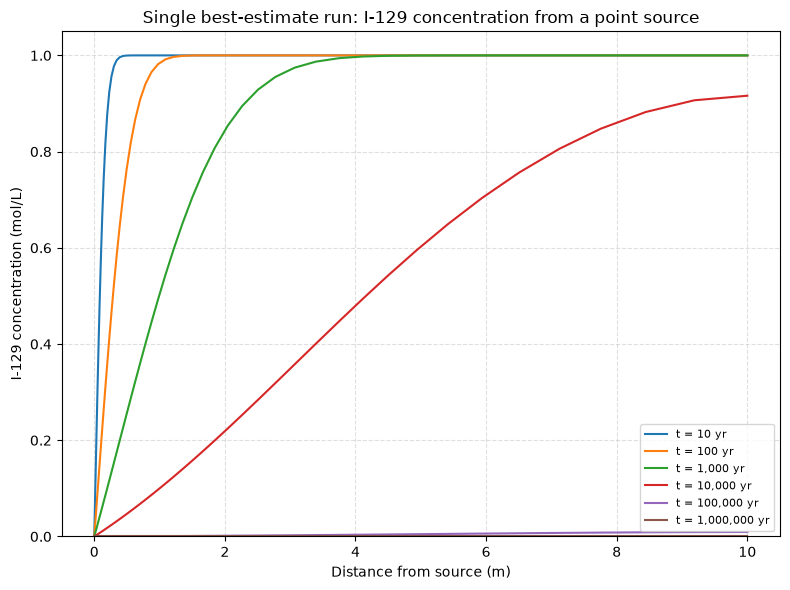

In [6]:
# Process and Plot Concentration Profiles
nuclide_results = results[NUCLIDE_NAME]
CONCENTRATION_FLOOR = 1e-20

SECONDS_PER_YEAR = 31557600.0
PLOT_TIMES_YEARS = [10, 100, 1_000, 10_000, 100_000, 1_000_000]

# Group a QoI's `{(z, t): [value]}` results into
# one distance-sorted profile per output time: dict[float, list[tuple[float, float]]]: `{t: [(distance, value), ...]}`,
# sorted by distance from the source.
by_time = {}
for (z, t), values in nuclide_results.items():
    by_time.setdefault(t, []).append((abs(z), values[0]))

for entries in by_time.values():
    entries.sort(key=lambda pair: pair[0])

available_times = sorted(by_time)

plt.figure(figsize=(8, 6))
for plot_time_years in PLOT_TIMES_YEARS:
    target_time_s = plot_time_years * SECONDS_PER_YEAR
    actual_time_s = min(available_times, key=lambda t: abs(t - target_time_s))

    distances = np.array([d for d, _ in by_time[actual_time_s]])
    concentrations = np.array([c for _, c in by_time[actual_time_s]])

    plt.plot(
        distances,
        np.clip(concentrations, CONCENTRATION_FLOOR, None),
        label=f"t = {plot_time_years:,.0f} yr",
    )

plt.xlabel("Distance from source (m)")
plt.ylabel(f"{NUCLIDE_NAME} concentration (mol/L)")
plt.ylim(bottom=CONCENTRATION_FLOOR)
plt.title("Single best-estimate run: I-129 concentration from a point source")
plt.legend(fontsize=8)
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 3. Ensemble run (uncertainty quantification)

Draws a small Sobol' ensemble over the six uncertain parameters, runs one OGS simulation per sample, and plots the ensemble mean and min-max band. Since the unit's thickness is itself uncertain, profiles are interpolated onto one common distance grid before the mean/min/max are computed.

In [7]:
! ./make_ensemble_samples.sh

In [8]:
! ./run_ensemble.sh

OGS samples:   0%|                                   | 0/8 [00:00<?, ?sample/s]Info    : Meshing 1D...
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [  0%] Meshing curve 1 (Line)
Info    : Meshing 1D...
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.00262692s, CPU 0.002551s)
Info    : Done meshing 1D (Wall 0.00263354s, CPU 0.002568s)
Info    : 50 nodes 54 elements
Info    : 50 nodes 54 elements
Inf

In [9]:
ENSEMBLE_OUTPUT_DIR = BASE_DIR / "output" / "ensemble_run"

# load results
results_file = max(ENSEMBLE_OUTPUT_DIR.glob("*.h5"), key=lambda p: p.stat().st_mtime)
ensemble_results = load_results_from_hdf5(str(results_file))["simulation_results"]

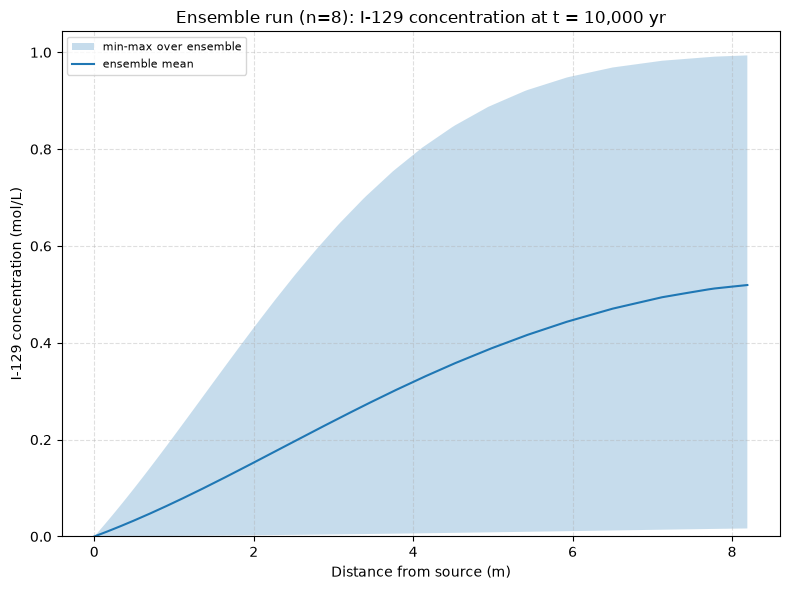

In [ ]:
# Process and Plot Ensemble Concentration Profiles
nuclide_results = ensemble_results[NUCLIDE_NAME]
SOURCE_LOC = 0.0
PLOT_TIME_YEARS = 10_000
COMMON_GRID_POINTS = 200

# Grouping each sample's own profile and interpolating onto a common distance grid
common_grid, means, mins, maxs, actual_time_s, n_samples = ensemble_profile_at_time(
    nuclide_results,
    PLOT_TIME_YEARS * SECONDS_PER_YEAR,
    source_loc=SOURCE_LOC,
    common_grid_points=COMMON_GRID_POINTS,
)
means = np.clip(means, CONCENTRATION_FLOOR, None)
mins = np.clip(mins, CONCENTRATION_FLOOR, None)
maxs = np.clip(maxs, CONCENTRATION_FLOOR, None)
actual_time_years = actual_time_s / SECONDS_PER_YEAR

plt.figure(figsize=(8, 6))
plt.fill_between(common_grid, mins, maxs, alpha=0.25, label="min-max over ensemble")
plt.plot(common_grid, means, label="ensemble mean")
plt.xlabel("Distance from source (m)")
plt.ylabel(f"{NUCLIDE_NAME} concentration (mol/L)")
plt.ylim(bottom=CONCENTRATION_FLOOR)
plt.title(
    f"Ensemble run (n={n_samples}): I-129 concentration at t = {actual_time_years:,.0f} yr"
)
plt.legend(fontsize=8)
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()